In [1]:
import seaborn as sns
import numpy as np
import pandas as pd
from sklearn.datasets import make_regression
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [33]:
sns.set_theme(style="whitegrid", palette="deep")

In [2]:
X,y = make_regression(n_samples=700, n_features=1, n_targets=1,noise=50, random_state=12)
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=12)

In [7]:
lr = LinearRegression()
lr.fit(X=X_train,y=y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [29]:
y_pred = lr.predict(X_test)

In [11]:
x_inp = np.linspace(X_train.min(), X_train.max(), 100)
line_slope = lr.coef_[0]
lr_line = line_slope * x_inp + lr.intercept_

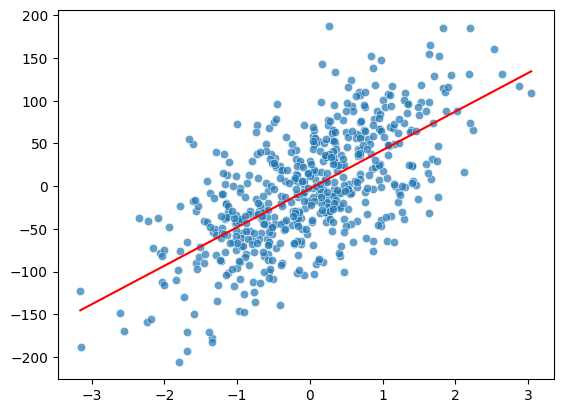

In [16]:
sns.scatterplot(x=X_train.ravel(), y=y_train, alpha=0.7)
plt.plot(x_inp, lr_line, color="red")

In [18]:
b = 0

In [26]:
l_slope = -2 * np.sum(line_slope * x_inp - b)
step_size = line_slope * 0.01
b = b-step_size
new_line = ((line_slope * x_inp) + b)

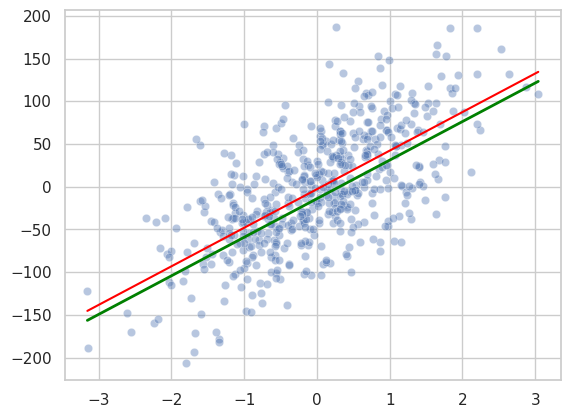

In [36]:
sns.scatterplot(x=X_train.ravel(), y=y_train, alpha=0.4)
plt.plot(x_inp, lr_line, color="red", label="LR Line")
plt.plot(x_inp,new_line, color="green", linewidth=2, label="Computed Line")